In [1]:
import socket, io, os
import numpy as np, pandas as pd, duckdb, requests
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.preprocessing import normalize
import umap

/Users/jabac/dev/mineria_youtube/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# IPv6 roto en la red: forzar IPv4 (para bajar miniaturas)
_orig = socket.getaddrinfo
socket.getaddrinfo = lambda h, p, f=0, *a, **k: _orig(h, p, socket.AF_INET, *a, **k)

# Seravek + respaldo para títulos en coreano, japonés, ruso, etc.
plt.rcParams["font.family"] = ["Seravek", "Arial Unicode MS", "Hiragino Sans", "DejaVu Sans"]
INK, MUTED, GRID = "#1f1f1e", "#6b6b66", "#e6e6e3"

def thumb(youtube_id):
    """Miniatura local si existe; si no, la baja de YouTube (para compañeros sin data/thumbs)."""
    path = f"data/thumbs/{youtube_id}.jpg"
    if os.path.exists(path):
        return Image.open(path)
    r = requests.get(f"https://i.ytimg.com/vi/{youtube_id}/mqdefault.jpg", timeout=15)
    return Image.open(io.BytesIO(r.content))

In [3]:
s = pd.read_parquet("data/multimodal_sample.parquet")
metricas = pd.read_csv("data/metricas_multimodal.csv", index_col="modelo")

Xt = np.stack(s["emb_text"]).astype(np.float32)    # texto
Xi = np.stack(s["emb_image"]).astype(np.float32)   # imagen
Xf = normalize(Xt + Xi)                            # fusión tardía
print(s.shape)
metricas


(5000, 17)


,knn_acc_original,knn_acc_umap,NMI_kmeans_umap
modelo,,,
TF-IDF,0.564,0.509,0.138
MiniLM,0.635,0.622,0.286
Texto (Gemma2),0.755,0.726,0.376
Imagen (Gemma2),0.742,0.732,0.392
Img+texto (Gemma2),0.770,0.736,0.362
Fusión texto+imagen,0.792,0.784,0.462
baseline mayoría,0.346,NaN,NaN


In [4]:
vocab = pd.read_parquet("data/emb_vocab.parquet")
L = np.stack(vocab["emb"]).astype(np.float32)      # (3806, 768) un vector por etiqueta
names = vocab["Name"].to_numpy()

S = Xi @ L.T                                        # similitud coseno imagen × etiqueta (5000, 3806)
top5 = np.argsort(-S, axis=1)[:, :5]
s["top5"] = [names[r].tolist() for r in top5]
s["top5_sim"] = [S[i, r].tolist() for i, r in enumerate(top5)]


findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


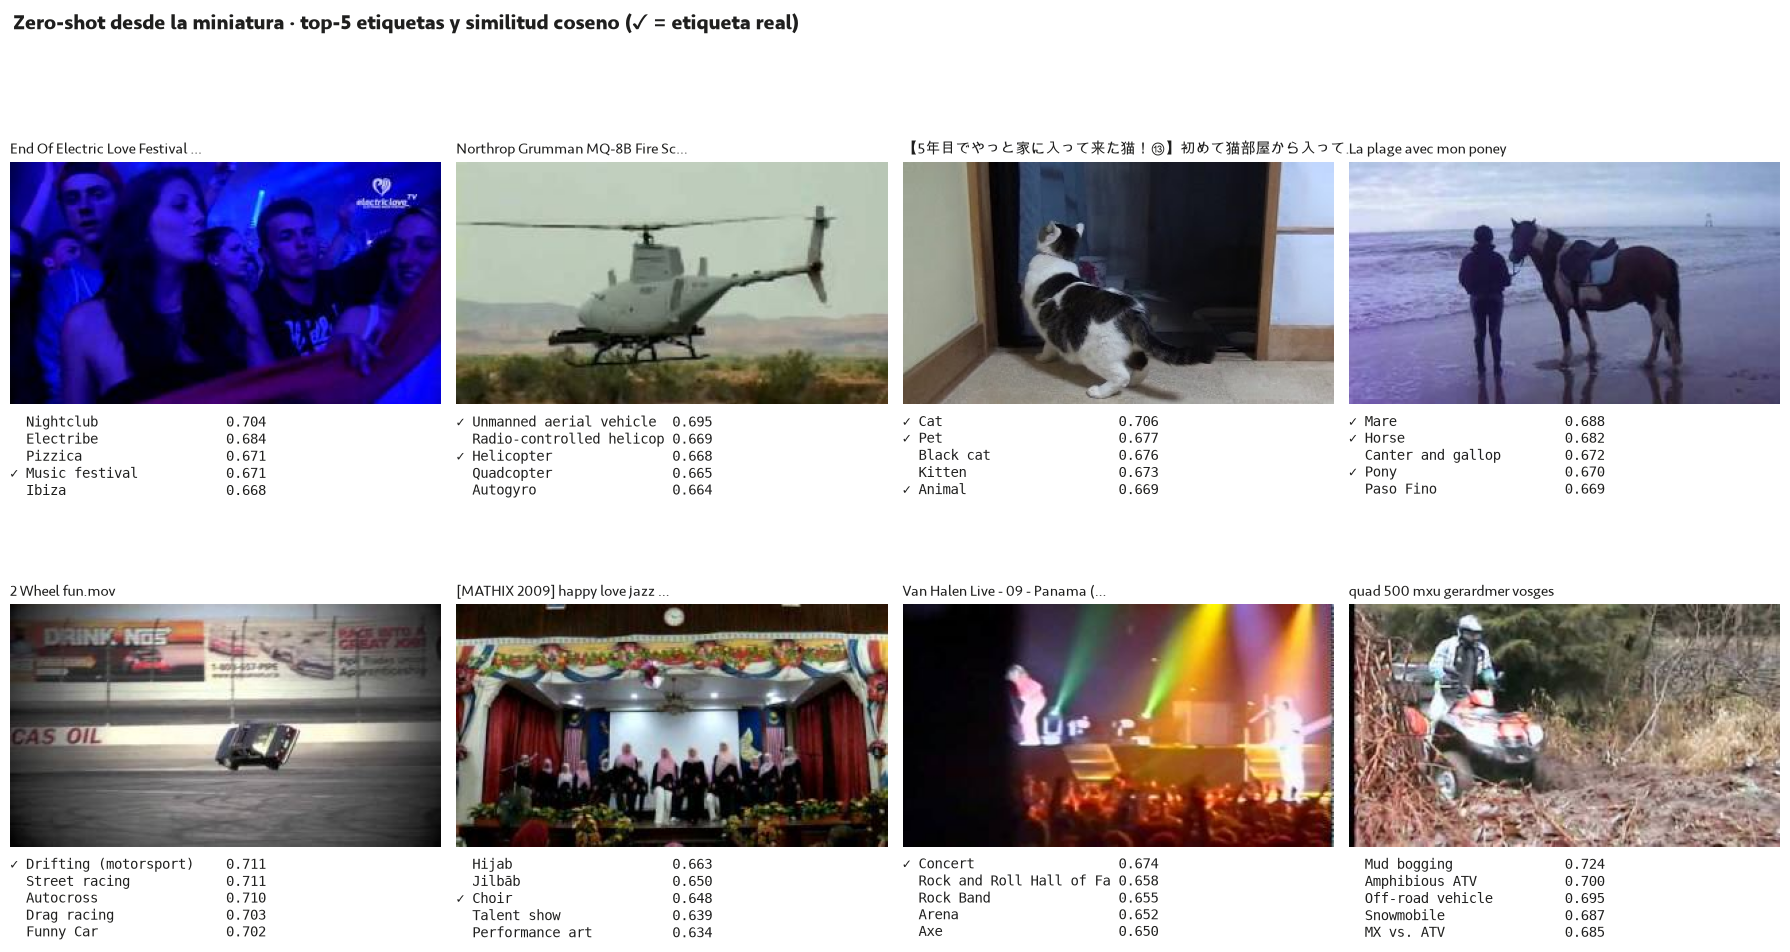

In [5]:
def corto(t, n):
    return t[:n] + ("…" if len(t) > n else "")

ej = s.sample(8, random_state=7)
fig, axes = plt.subplots(2, 4, figsize=(18, 9.5))
for ax, (_, r) in zip(axes.flat, ej.iterrows()):
    ax.imshow(thumb(r.youtube_id)); ax.axis("off")
    reales = set(r.label_names)
    lineas = [f"{'✓' if p in reales else ' '} {p[:24]:<24} {sim:.3f}" for p, sim in zip(r.top5, r.top5_sim)]
    ax.set_title(corto(r.title, 30), fontsize=11, color=INK, loc="left")
    ax.text(0, -0.04, "\n".join(lineas), transform=ax.transAxes, va="top",
            fontsize=10, color=INK, family="DejaVu Sans Mono")
fig.suptitle("Zero-shot desde la miniatura · top-5 etiquetas y similitud coseno (✓ = etiqueta real)",
             x=0.01, ha="left", fontsize=15, fontweight="bold", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.95), h_pad=8)
plt.show()


findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


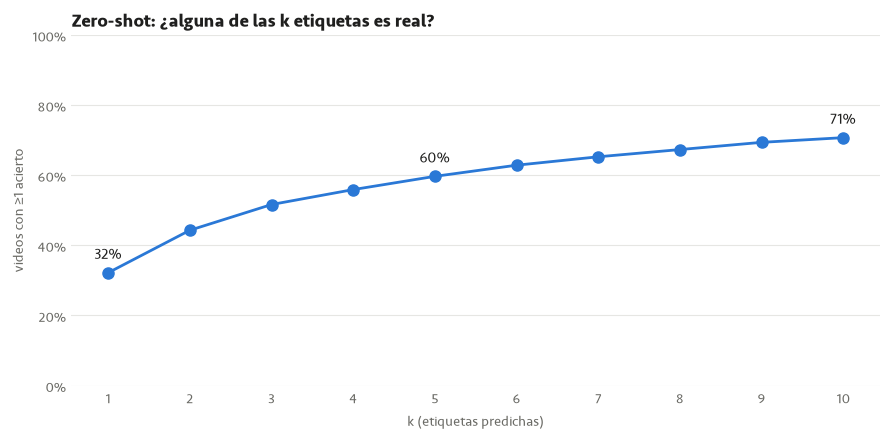

In [6]:
ks = range(1, 11)
hits = [np.mean([len(set(p[:k]) & set(l)) > 0 for p, l in zip(s.pred_names, s.label_names)]) for k in ks]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(ks, hits, color="#2a78d6", lw=2, marker="o", ms=8, zorder=3)
for k in (1, 5, 10):
    ax.annotate(f"{hits[k-1]:.0%}", (k, hits[k-1]), textcoords="offset points",
                xytext=(0, 10), ha="center", fontsize=11, color=INK)
ax.set_xticks(list(ks)); ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("k (etiquetas predichas)", color=MUTED); ax.set_ylabel("videos con ≥1 acierto", color=MUTED)
ax.set_title("Zero-shot: ¿alguna de las k etiquetas es real?", loc="left", fontsize=13, fontweight="bold", color=INK)
ax.grid(axis="y", color=GRID); ax.grid(axis="x", visible=False)
for sp in ax.spines.values(): sp.set_visible(False)
ax.tick_params(colors=MUTED, length=0)
plt.tight_layout(); plt.show()


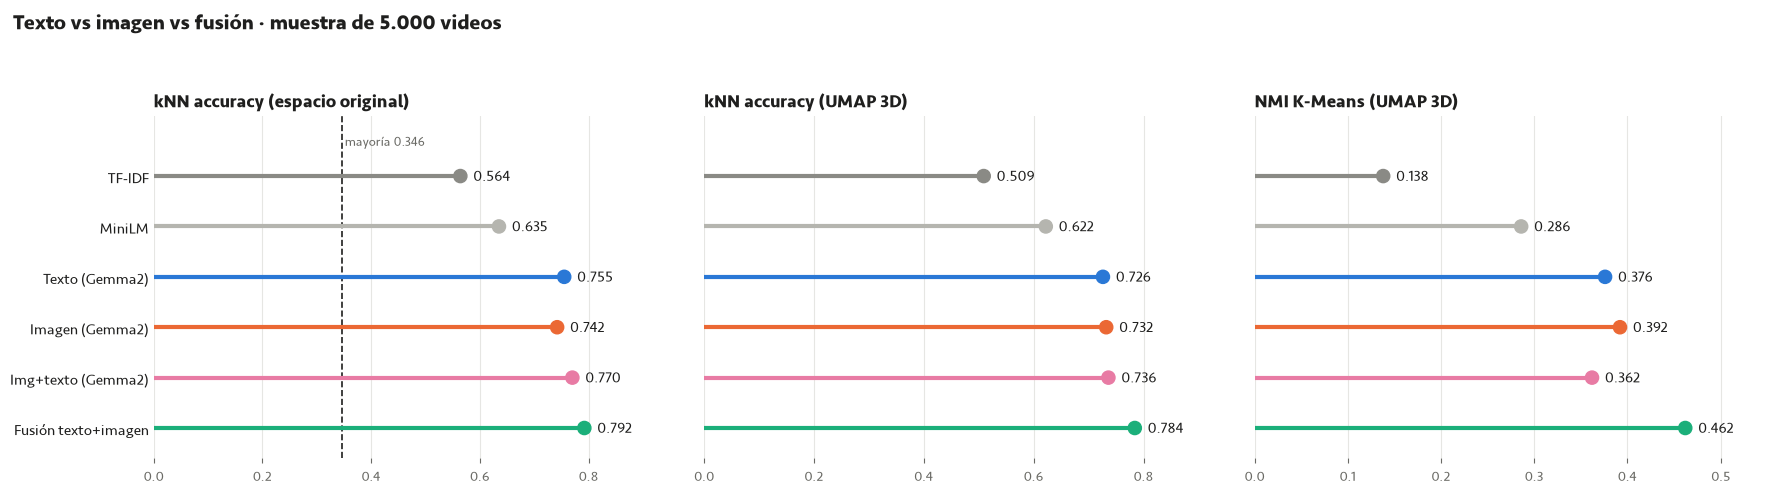

In [7]:
COLORS = {"TF-IDF": "#8a8a85", "MiniLM": "#b5b5af", "Texto (Gemma2)": "#2a78d6",
          "Imagen (Gemma2)": "#eb6834", "Img+texto (Gemma2)": "#e87ba4", "Fusión texto+imagen": "#1baf7a"}
PANELS = [("knn_acc_original", "kNN accuracy (espacio original)"),
          ("knn_acc_umap",     "kNN accuracy (UMAP 3D)"),
          ("NMI_kmeans_umap",  "NMI K-Means (UMAP 3D)")]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, (col, title) in zip(axes, PANELS):
    m = metricas.loc[[n for n in COLORS if n in metricas.index], col].dropna()
    ypos = np.arange(len(m))[::-1]; colors = [COLORS[n] for n in m.index]
    ax.hlines(ypos, 0, m.values, color=colors, lw=3, zorder=3)
    ax.scatter(m.values, ypos, color=colors, s=90, zorder=4)
    for yy, v in zip(ypos, m.values):
        ax.text(v + m.max() * 0.03, yy, f"{v:.3f}", va="center", fontsize=11, color=INK)
    if col == "knn_acc_original" and "baseline mayoría" in metricas.index:
        b = metricas.loc["baseline mayoría", col]
        ax.axvline(b, color=INK, ls="--", lw=1.2)
        ax.text(b, ypos.max() + 0.6, f" mayoría {b:.3f}", fontsize=9.5, color=MUTED)
    ax.set_xlim(0, m.max() * 1.22); ax.set_yticks(ypos, m.index, fontsize=11, color=INK)
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold", color=INK)
    ax.grid(axis="x", color=GRID, zorder=0); ax.grid(axis="y", visible=False)
    ax.tick_params(axis="x", colors=MUTED); ax.tick_params(axis="y", length=0)
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.set_ylim(-0.6, ypos.max() + 1.2)
fig.suptitle("Texto vs imagen vs fusión · muestra de 5.000 videos",
             x=0.01, ha="left", fontsize=15, fontweight="bold", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.93)); plt.show()


In [8]:
import plotly.express as px

def plot3d(name, data, title, point_size=2):
    fig = px.scatter_3d(data, x=f"{name}_x", y=f"{name}_y", z=f"{name}_z",
                        color="vertical", hover_name="title", opacity=0.6,
                        title=title, height=750,
                        color_discrete_sequence=px.colors.qualitative.Alphabet,
                        category_orders={"vertical": data["vertical"].value_counts().index.tolist()})
    fig.update_traces(marker_size=point_size)
    fig.update_layout(legend=dict(itemsizing="constant",   # símbolos grandes en la leyenda
                                  font_size=14,
                                  title_text="Categoría"))
    return fig

In [9]:
plot3d("texto",  data=s, title="UMAP 3D · Texto")


In [10]:
plot3d("imagen", data=s, title="UMAP 3D · Imagen")


In [11]:
plot3d("fusion", data=s, title="UMAP 3D · Fusión texto + imagen")


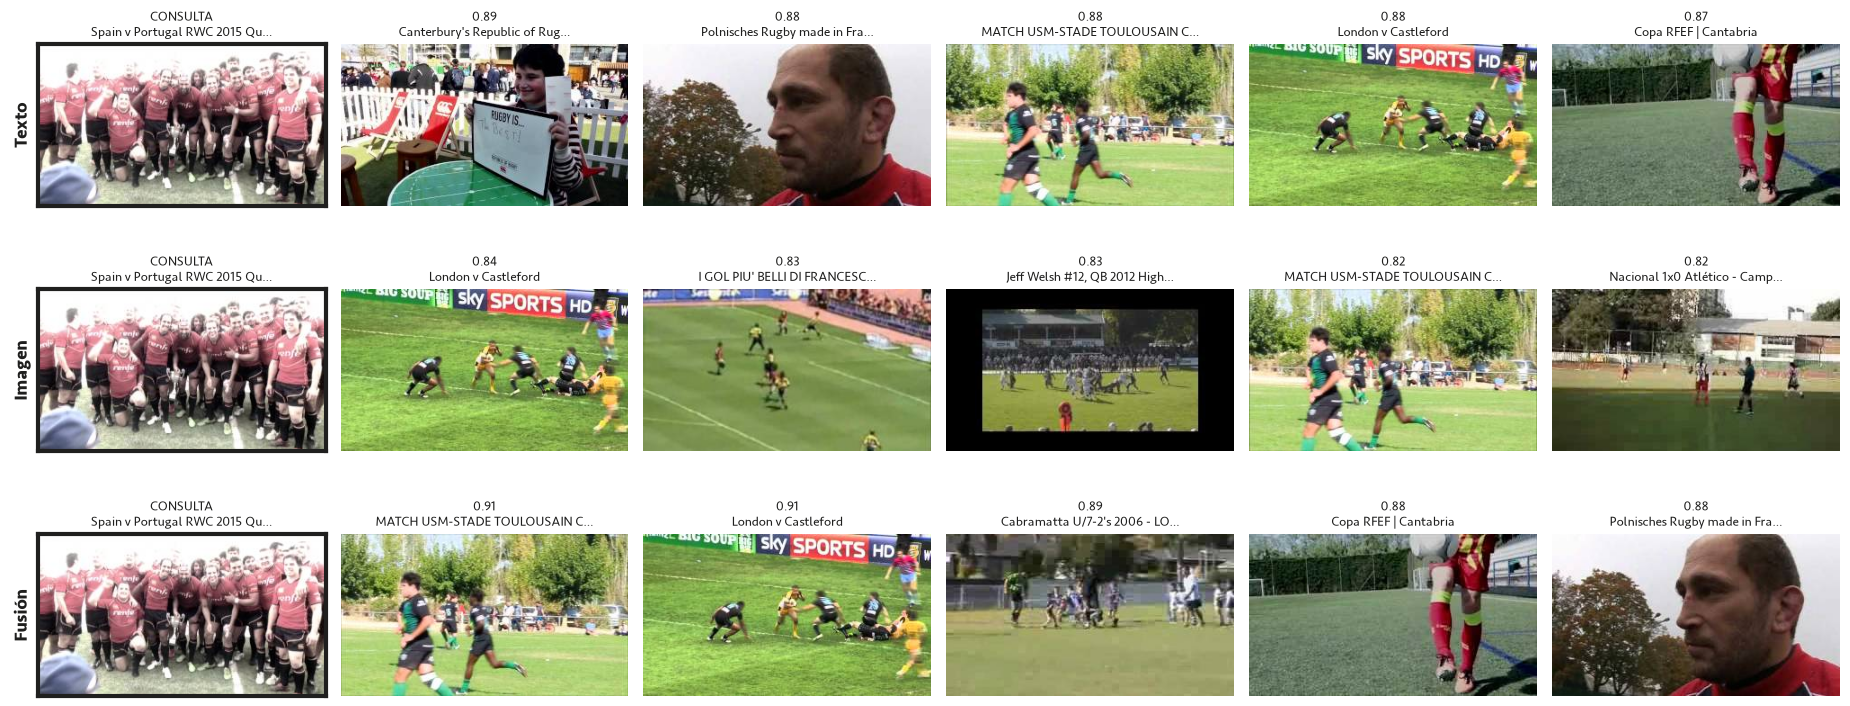

In [12]:
def vecinos(i, n=5):
    reps = {"Texto": Xt, "Imagen": Xi, "Fusión": Xf}
    fig, axes = plt.subplots(len(reps), n + 1, figsize=(3.1 * (n + 1), 2.6 * len(reps)))
    for row, (nombre, X) in zip(axes, reps.items()):
        sims = X @ X[i]
        idx = np.argsort(-sims)[: n + 1]            # el primero es el mismo video
        for j, (ax, k) in enumerate(zip(row, idx)):
            ax.imshow(thumb(s.youtube_id.iloc[k])); ax.set_xticks([]); ax.set_yticks([])
            for sp in ax.spines.values():
                sp.set_visible(j == 0); sp.set_color(INK); sp.set_linewidth(3)
            t = s.title.iloc[k]
            ax.set_title(("CONSULTA\n" if j == 0 else f"{sims[k]:.2f}\n") + t[:28] + ("…" if len(t) > 28 else ""),
                         fontsize=9, color=INK)
        row[0].set_ylabel(nombre, fontsize=13, fontweight="bold", color=INK)
    fig.tight_layout(); plt.show()

# buscar un video por título y mostrar sus vecinos
i = s.index[s.title.str.contains("rugby", case=False, na=False)][0]
vecinos(i)


In [13]:
# palabras: las que son top-1 de al menos 5 imágenes (~200; con las 3.800 el mapa queda ilegible)
top1 = pd.Series([t[0] for t in s["top5"]]).value_counts()
W = vocab[vocab["Name"].isin(top1[top1 >= 5].index)].reset_index(drop=True)
Lw = np.stack(W["emb"]).astype(np.float32)

def mapa_conjunto(centrar=True):
    # centrar = restar el promedio de cada modalidad → cierra la brecha imagen/texto
    A, B = (normalize(Xi - Xi.mean(0)), normalize(Lw - Lw.mean(0))) if centrar else (Xi, Lw)
    U = umap.UMAP(n_components=3, metric="cosine", n_neighbors=15, min_dist=0.1,
                  random_state=42).fit_transform(np.vstack([A, B]))
    n = len(A)
    df = pd.concat([
        pd.DataFrame({"x": U[:n, 0], "y": U[:n, 1], "z": U[:n, 2], "tipo": "imagen",
                      "texto": s["title"], "detalle": [", ".join(t[:3]) for t in s["top5"]],
                      "categoria": s["vertical"]}),
        pd.DataFrame({"x": U[n:, 0], "y": U[n:, 1], "z": U[n:, 2], "tipo": "palabra",
                      "texto": W["Name"], "detalle": W["Name"].map(top1).astype(str) + " imágenes la tienen como top-1",
                      "categoria": W["Vertical1"].fillna("(Unknown)")}),
    ], ignore_index=True)

    fig = px.scatter_3d(df, x="x", y="y", z="z", color="tipo", symbol="tipo", hover_name="texto",
                        hover_data={"detalle": True, "categoria": True, "x": False, "y": False, "z": False, "tipo": False},
                        color_discrete_map={"imagen": "#b5b5af", "palabra": "#eb6834"},
                        symbol_map={"imagen": "circle", "palabra": "diamond"}, opacity=0.7, height=750,
                        title="Imágenes y palabras en el mismo espacio" + (" (centrado por modalidad)" if centrar else " (crudo)"))
    fig.for_each_trace(lambda t: t.update(marker_size=2 if t.name == "imagen" else 5))
    fig.update_layout(legend=dict(itemsizing="constant", font_size=14, title_text=""))
    return fig

mapa_conjunto(centrar=True)


/Users/jabac/dev/mineria_youtube/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
